In [ ]:
!pip install gdown

### Load data (from PlanetAlign)

In [ ]:
from typing import Union, Optional
from pathlib import Path
import os
import gdown

# from PlanetAlign.data import Dataset

USER_AGENT = 'PlanetAlign'

def download_file_from_google_drive(
		remote_file_id: str,
		root: Union[str, Path],
		save_filename: Optional[Union[str, Path]] = None):
	r"""Download a file from Google Drive."""

	root = os.path.expanduser(root)
	if not save_filename:
		save_filename = remote_file_id
	fpath = os.fspath(os.path.join(root, save_filename))

	fname = save_filename.split('.')[0]
	os.makedirs(root, exist_ok=True)
	if os.path.isfile(fpath):
		print(f'Dataset "{fname}" is already downloaded')
		return
	else:
		print(f'Downloading dataset "{fname}"...')

	gdown.download(id=remote_file_id, output=fpath, quiet=False, user_agent=USER_AGENT)

if __name__ == '__main__':
	# Download the Phone-Email dataset
	download_file_from_google_drive(
		remote_file_id='13BklpBEFjT73Xk8H-daPGzBx-xFbpO0P',
		save_filename='phone_email.pt',
		root="data")
	
	download_file_from_google_drive(
		remote_file_id='1zfZc6So7UEyVZHN-Uas-eAgckqk28gal',
		save_filename='flickr-lastfm.pt',
		root="data")
	
	download_file_from_google_drive(
		remote_file_id='1PMtPhwEPKUr-PP8LnYoYADh7-x22xbZ4',
		save_filename='douban.pt',
		root="data")
	
	download_file_from_google_drive(
		remote_file_id='1B0Mit89nVk7ZnymTfGYHFZRRckV55neO',
		save_filename='flickr-myspace.pt',
		root="data")
	
	download_file_from_google_drive(
		remote_file_id='1-MecFHVRnlvqjmUbSGCizdvsedsiET98',
		save_filename='ACM-DBLP.pt',
		root="data")

	download_file_from_google_drive(
		remote_file_id='1cG9DoOxUcpCzWgWsxyTlp4XvHGNkY-oF',
		save_filename='cora.pt',
		root="data")
	# phone_email = Dataset(root='../../datasets', name='phone_email', train_ratio=0.2)
	# print(phone_email)

In [ ]:
# ============================================================
# Statistical analysis of GIN, GINE and GCNRes
# ============================================================

import pandas as pd
import numpy as np

from scipy.stats import friedmanchisquare
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# ============================================================
# 1. PARAMETERS
# ============================================================

FILE = "experiments/output/Final_experiments-Summary.csv"

ENCODERS = ["GCNRes", "GIN", "GINE"]

METRICS = [
	"Hits@1",
	"Hits@10",
	"MRR",
	"Runtime"
]

DATASETS = [
	"Cora",
	"ACM-DBLP",
	"Douban"
]


# ============================================================
# 2. LOAD DATA
# ============================================================

df = pd.read_csv(
	FILE,
	decimal=","
)
df

,Dataset,Encoder,Dimension,Layer,Seed,Accuracy,Hits@1,Hits@10,Hits@30,Hits@50,MRR,Runtime
0,Cora,GIN,8,2,1,0.5140,0.4978,0.8384,0.9315,0.9599,0.6178,5.2288
1,Cora,GIN,8,2,2,0.5281,0.5048,0.8303,0.9169,0.9457,0.6192,7.7280
2,Cora,GIN,8,2,3,0.5162,0.5004,0.8379,0.9212,0.9487,0.6170,5.5764
3,Cora,GIN,8,2,4,0.5447,0.5205,0.8375,0.9265,0.9551,0.6318,6.0317
4,Cora,GIN,8,2,5,0.5133,0.4884,0.8213,0.9119,0.9404,0.6025,8.1230
...,...,...,...,...,...,...,...,...,...,...,...,...
2875,Douban,GCNRes,1024,12,6,0.2710,0.2442,0.5487,0.7071,0.7634,0.3467,16.4996
2876,Douban,GCNRes,1024,12,7,0.2719,0.2455,0.5470,0.6999,0.7652,0.3473,14.5050
2877,Douban,GCNRes,1024,12,8,0.2701,0.2460,0.5461,0.7048,0.7603,0.3481,17.3976
2878,Douban,GCNRes,1024,12,9,0.2674,0.2433,0.5461,0.7026,0.7652,0.3457,14.3986


In [ ]:
# ============================================================
# 3. CHECK DATA
# ============================================================

print("\nObservations per dataset:")
print(df["Dataset"].value_counts())

print("\nObservations per encoder:")
print(df["Encoder"].value_counts())

print("\nObservations per Dataset × Encoder:")
print(
		df.groupby(["Dataset", "Encoder"])
			.size()
)

In [ ]:
# ============================================================
# 4. NUMERIC VARIABLES
# ============================================================

numeric_columns = [
	"Dimension",
	"Layer",
	"Seed",
	"Accuracy",
	"Hits@1",
	"Hits@10",
	"Hits@30",
	"Hits@50",
	"MRR",
	"Runtime"
]

for col in numeric_columns:
	df[col] = pd.to_numeric(
		df[col],
		errors="coerce"
	)

In [ ]:
# ============================================================
# 5. DESCRIPTIVE STATISTICS
# ============================================================

print("\n============================================================")
print("DESCRIPTIVE STATISTICS")
print("============================================================")

descriptive = (
	df
	.groupby(["Dataset", "Encoder"])[METRICS]
	.agg(["mean", "std"])
)

# print(descriptive)


# Save descriptive statistics
""" descriptive.to_csv(
	"descriptive_statistics.csv"
) """
descriptive


DESCRIPTIVE STATISTICS


Hits@1             Hits@10                 MRR            \
                      mean       std      mean       std      mean       std   
Dataset  Encoder                                                               
ACM-DBLP GCNRes   0.566495  0.058875  0.859234  0.033415  0.665840  0.050509   
         GIN      0.559303  0.054282  0.840434  0.031898  0.654064  0.046693   
         GINE     0.569943  0.048184  0.854399  0.032557  0.665772  0.043221   
Cora     GCNRes   0.860215  0.138868  0.961407  0.043069  0.898332  0.105642   
         GIN      0.881429  0.155293  0.971677  0.052965  0.915964  0.119779   
         GINE     0.884864  0.153316  0.971567  0.051651  0.917746  0.118260   
Douban   GCNRes   0.237121  0.019222  0.539732  0.028176  0.337358  0.021812   
         GIN      0.314884  0.043482  0.567221  0.052875  0.401203  0.046300   
         GINE     0.223933  0.035463  0.452477  0.058577  0.300858  0.042642   

                     Runtime             
                        mean        std  
Dataset  Encoder                         
ACM-DBLP GCNRes    39.163939  21.199186  
         GIN       69.554390  35.684374  
         GINE     131.347128  83.837210  
Cora     GCNRes    10.490187   6.284377  
         GIN       24.420633  15.402681  
         GINE      36.313623  24.167998  
Douban   GCNRes     5.910367   3.381788  
         GIN       12.852045   6.737236  
         GINE      21.820819  15.036496

In [ ]:
# ============================================================
# 6. AGGREGATE THE 10 SEEDS
# ============================================================
#
# Each configuration is:
#
# Dataset × Dimension × Layer × Encoder
#
# There are 10 seeds per configuration.
#
# We average the 10 seeds before the inferential test.
#
# This gives:
#
# 3 datasets × 8 dimensions × 4 layers = 96 blocks
#
# ============================================================

config_cols = [
	"Dataset",
	"Dimension",
	"Layer",
	"Encoder"
]

config_df = (
	df
	.groupby(config_cols)[METRICS]
	.mean()
	.reset_index()
)

print("\n============================================================")
print("CONFIGURATION-LEVEL DATA")
print("============================================================")

# print(config_df.head())
config_df


CONFIGURATION-LEVEL DATA


,Dataset,Dimension,Layer,Encoder,Hits@1,Hits@10,MRR,Runtime
0,ACM-DBLP,8,2,GCNRes,0.49071,0.81924,0.60216,15.64780
1,ACM-DBLP,8,2,GIN,0.47383,0.79988,0.58347,22.25222
2,ACM-DBLP,8,2,GINE,0.48113,0.80032,0.58828,34.20010
3,ACM-DBLP,8,4,GCNRes,0.42535,0.77830,0.54450,17.57712
4,ACM-DBLP,8,4,GIN,0.44128,0.77525,0.55291,43.23904
...,...,...,...,...,...,...,...,...
283,Douban,1024,8,GIN,0.35666,0.61786,0.44555,20.41268
284,Douban,1024,8,GINE,0.24929,0.47984,0.32611,28.18023
285,Douban,1024,12,GCNRes,0.24445,0.54633,0.34675,15.01291
286,Douban,1024,12,GIN,0.34759,0.60492,0.43493,24.25426


In [ ]:
# ============================================================
# 7. FUNCTION: FRIEDMAN TEST
# ============================================================

def friedman_test(
	data,
	metric,
	dataset=None
):

	if dataset is not None:

		data = data[
			data["Dataset"] == dataset
		]

	# Pivot:
	#
	# rows    = Dataset × Dimension × Layer
	# columns = Encoder
	#
	# Example:
	#
	#             GCNRes     GIN      GINE
	# block 1      ...
	# block 2      ...
	#
	pivot = (
		data
		.pivot_table(
			index=[
				"Dataset",
				"Dimension",
				"Layer"
			],
			columns="Encoder",
			values=metric
		)
		.dropna()
	)

	statistic, p_value = friedmanchisquare(
		pivot["GCNRes"],
		pivot["GIN"],
		pivot["GINE"]
	)

	return statistic, p_value, pivot

# ============================================================
# 8. FUNCTION: WILCOXON + HOLM
# ============================================================

def posthoc_wilcoxon(
	pivot,
	metric
):

	pairs = [
		("GIN", "GINE"),
		("GIN", "GCNRes"),
		("GINE", "GCNRes")
	]

	results = []

	raw_pvalues = []

	for encoder1, encoder2 in pairs:

		x = pivot[encoder1]
		y = pivot[encoder2]

		statistic, p_value = wilcoxon(
			x,
			y,
			alternative="two-sided"
		)

		raw_pvalues.append(p_value)

		results.append({
			"Metric": metric,
			"Comparison": f"{encoder1} vs {encoder2}",
			"Statistic": statistic,
			"p_raw": p_value
		})

	# Holm correction
	reject, p_adjusted, _, _ = multipletests(
		raw_pvalues,
		method="holm"
	)

	for i, result in enumerate(results):

		result["p_adjusted"] = p_adjusted[i]
		result["Significant"] = reject[i]

	return pd.DataFrame(results)

# ============================================================
# 9. FUNCTION: AVERAGE RANK
# ============================================================

def average_ranks(
	pivot,
	higher_is_better=True
):

	rank_data = pivot.copy()

	if higher_is_better:

		# Highest value = rank 1
		ranks = rank_data.rank(
			axis=1,
			ascending=False,
			method="average"
		)

	else:

		# Lowest value = rank 1
		ranks = rank_data.rank(
			axis=1,
			ascending=True,
			method="average"
		)

	return ranks.mean().sort_values()

# ============================================================
# 10. COMPLETE ANALYSIS FOR ONE DATASET
# ============================================================

def analyze_dataset(
	data,
	dataset,
	metric,
	higher_is_better=True
):

	print("\n")
	print("=" * 70)
	print(f"DATASET: {dataset}")
	print(f"METRIC: {metric}")
	print("=" * 70)

	# --------------------------------------------------------
	# Friedman
	# --------------------------------------------------------

	statistic, p_value, pivot = friedman_test(
		data,
		metric,
		dataset
	)

	print("\nFriedman test")
	print("-----------------------------")

	print(f"Chi-square = {statistic:.6f}")
	print(f"p-value    = {p_value:.6e}")

	if p_value < 0.05:
		print("Result     = Significant")
	else:
		print("Result     = Not significant")

	# --------------------------------------------------------
	# Average ranks
	# --------------------------------------------------------

	ranks = average_ranks(
		pivot,
		higher_is_better
	)

	print("\nAverage ranks")
	print("-----------------------------")

	print(ranks)

	# --------------------------------------------------------
	# Post-hoc
	# --------------------------------------------------------

	if p_value < 0.05:

		posthoc = posthoc_wilcoxon(
			pivot,
			metric
		)

		print("\nPost-hoc Wilcoxon + Holm")
		print("-----------------------------")

		print(
			posthoc.to_string(
				index=False
			)
		)

	else:

		posthoc = None

		print(
			"\nOmnibus Friedman test was not significant."
		)

	return {
		"dataset": dataset,
		"metric": metric,
		"friedman_statistic": statistic,
		"friedman_p": p_value,
		"ranks": ranks,
		"posthoc": posthoc}

In [ ]:
# ============================================================
# 11. ANALYSIS BY DATASET
# ============================================================

all_results = []

for metric in METRICS:
	""" print("\n\n")
	print("#" * 80)
	print(f"METRIC: {metric}")
	print("#" * 80) """

	for dataset in DATASETS:

		# Runtime: lower is better
		if metric == "Runtime":
			higher_is_better = False
		else:
			higher_is_better = True

		result = analyze_dataset(
			config_df,
			dataset,
			metric,
			higher_is_better
		)

		all_results.append(result)
all_results



DATASET: Cora
METRIC: Hits@1

Friedman test
-----------------------------
Chi-square = 27.228346
p-value    = 1.223037e-06
Result     = Significant

Average ranks
-----------------------------
Encoder
GIN       1.609375
GINE      1.640625
GCNRes    2.750000
dtype: float64

Post-hoc Wilcoxon + Holm
-----------------------------
Metric     Comparison  Statistic    p_raw  p_adjusted  Significant
Hits@1    GIN vs GINE      196.0 0.308193    0.308193        False
Hits@1  GIN vs GCNRes       49.0 0.000013    0.000025         True
Hits@1 GINE vs GCNRes       32.0 0.000001    0.000004         True


DATASET: ACM-DBLP
METRIC: Hits@1

Friedman test
-----------------------------
Chi-square = 5.687500
p-value    = 5.820698e-02
Result     = Not significant

Average ranks
-----------------------------
Encoder
GINE      1.71875
GCNRes    1.96875
GIN       2.31250
dtype: float64

Omnibus Friedman test was not significant.


DATASET: Douban
METRIC: Hits@1

Friedman test
-----------------------------


/home/ealvarez/miniconda3/envs/graph_matching/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)



Friedman test
-----------------------------
Chi-square = 58.562500
p-value    = 1.920060e-13
Result     = Significant

Average ranks
-----------------------------
Encoder
GIN       1.00000
GCNRes    2.09375
GINE      2.90625
dtype: float64

Post-hoc Wilcoxon + Holm
-----------------------------
Metric     Comparison  Statistic        p_raw   p_adjusted  Significant
   MRR    GIN vs GINE        0.0 4.656613e-10 1.396984e-09         True
   MRR  GIN vs GCNRes        0.0 4.656613e-10 1.396984e-09         True
   MRR GINE vs GCNRes       10.0 2.002344e-08 2.002344e-08         True


DATASET: Cora
METRIC: Runtime

Friedman test
-----------------------------
Chi-square = 64.000000
p-value    = 1.266417e-14
Result     = Significant

Average ranks
-----------------------------
Encoder
GCNRes    1.0
GIN       2.0
GINE      3.0
dtype: float64

Post-hoc Wilcoxon + Holm
-----------------------------
 Metric     Comparison  Statistic        p_raw   p_adjusted  Significant
Runtime    GIN vs GINE   

[{'dataset': 'Cora',
  'metric': 'Hits@1',
  'friedman_statistic': 27.228346456692915,
  'friedman_p': 1.2230372689401747e-06,
  'ranks': Encoder
  GIN       1.609375
  GINE      1.640625
  GCNRes    2.750000
  dtype: float64,
  'posthoc':    Metric      Comparison  Statistic     p_raw  p_adjusted  Significant
  0  Hits@1     GIN vs GINE      196.0  0.308193    0.308193        False
  1  Hits@1   GIN vs GCNRes       49.0  0.000013    0.000025         True
  2  Hits@1  GINE vs GCNRes       32.0  0.000001    0.000004         True},
 {'dataset': 'ACM-DBLP',
  'metric': 'Hits@1',
  'friedman_statistic': 5.6875,
  'friedman_p': 0.058206980009571974,
  'ranks': Encoder
  GINE      1.71875
  GCNRes    1.96875
  GIN       2.31250
  dtype: float64,
  'posthoc': None},
 {'dataset': 'Douban',
  'metric': 'Hits@1',
  'friedman_statistic': 49.5625,
  'friedman_p': 1.7283825395474507e-11,
  'ranks': Encoder
  GIN       1.00000
  GCNRes    2.34375
  GINE      2.65625
  dtype: float64,
  'posthoc':   

In [ ]:
# ============================================================
# 12. GLOBAL ANALYSIS
# ============================================================
#
# All three datasets together.
#
# Blocks:
#
# Dataset × Dimension × Layer
#
# = 3 × 8 × 4
# = 96 blocks
#
# ============================================================

print("\n\n")
print("#" * 80)
print("GLOBAL ANALYSIS — ALL DATASETS")
print("#" * 80)


global_results = []


for metric in METRICS:

	print("\n")
	print("=" * 70)
	print(f"METRIC: {metric}")
	print("=" * 70)

	higher_is_better = (
		False if metric == "Runtime"
		else True
	)

	statistic, p_value, pivot = friedman_test(
		config_df,
		metric
	)

	print("\nFriedman test")
	print("-----------------------------")

	print(f"Chi-square = {statistic:.6f}")
	print(f"p-value    = {p_value:.6e}")

	# --------------------------------------------------------
	# Average rank
	# --------------------------------------------------------

	ranks = average_ranks(
		pivot,
		higher_is_better
	)

	print("\nAverage ranks")
	print("-----------------------------")

	print(ranks)

	# --------------------------------------------------------
	# Post-hoc
	# --------------------------------------------------------

	if p_value < 0.05:

		posthoc = posthoc_wilcoxon(
			pivot,
			metric
		)

		print("\nPost-hoc Wilcoxon + Holm")
		print("-----------------------------")

		print(
			posthoc.to_string(
				index=False
			)
		)

	else:

		posthoc = None

		print(
			"\nFriedman test is not significant."
		)

	global_results.append({
		"Metric": metric,
		"Friedman_statistic": statistic,
		"Friedman_p": p_value,
		"Best_encoder": ranks.index[0],
		"Best_rank": ranks.iloc[0]
	})
global_results




################################################################################
GLOBAL ANALYSIS — ALL DATASETS
################################################################################


METRIC: Hits@1

Friedman test
-----------------------------
Chi-square = 24.506527
p-value    = 4.769526e-06

Average ranks
-----------------------------
Encoder
GIN       1.640625
GINE      2.005208
GCNRes    2.354167
dtype: float64

Post-hoc Wilcoxon + Holm
-----------------------------
Metric     Comparison  Statistic        p_raw   p_adjusted  Significant
Hits@1    GIN vs GINE     1520.0 4.787188e-03 9.574376e-03         True
Hits@1  GIN vs GCNRes      767.0 1.167679e-08 3.503037e-08         True
Hits@1 GINE vs GCNRes     1733.0 2.968149e-02 2.968149e-02         True


METRIC: Hits@10

Friedman test
-----------------------------
Chi-square = 1.937500
p-value    = 3.795572e-01

Average ranks
-----------------------------
Encoder
GIN       1.927083
GCNRes    1.958333
GINE      2.114583
dty

[{'Metric': 'Hits@1',
  'Friedman_statistic': 24.506527415143527,
  'Friedman_p': 4.769525625587812e-06,
  'Best_encoder': 'GIN',
  'Best_rank': 1.640625},
 {'Metric': 'Hits@10',
  'Friedman_statistic': 1.9375,
  'Friedman_p': 0.37955718818308953,
  'Best_encoder': 'GIN',
  'Best_rank': 1.9270833333333333},
 {'Metric': 'MRR',
  'Friedman_statistic': 7.2708333333332575,
  'Friedman_p': 0.026372943371384402,
  'Best_encoder': 'GIN',
  'Best_rank': 1.7916666666666667},
 {'Metric': 'Runtime',
  'Friedman_statistic': 188.08333333333326,
  'Friedman_p': 1.4395378809684863e-41,
  'Best_encoder': 'GCNRes',
  'Best_rank': 1.0}]

In [ ]:
# ============================================================
# 13. GLOBAL RESULTS TABLE
# ============================================================

global_results_df = pd.DataFrame(
	global_results
)

print("\n\n")
print("=" * 80)
print("GLOBAL RESULTS SUMMARY")
print("=" * 80)

print(
	global_results_df.to_string(
		index=False
	)
)

""" global_results_df.to_csv(
	"global_friedman_results.csv",
	index=False
) """
global_results_df




GLOBAL RESULTS SUMMARY
 Metric  Friedman_statistic   Friedman_p Best_encoder  Best_rank
 Hits@1           24.506527 4.769526e-06          GIN   1.640625
Hits@10            1.937500 3.795572e-01          GIN   1.927083
    MRR            7.270833 2.637294e-02          GIN   1.791667
Runtime          188.083333 1.439538e-41       GCNRes   1.000000


,Metric,Friedman_statistic,Friedman_p,Best_encoder,Best_rank
0,Hits@1,24.506527,4.769526e-06,GIN,1.640625
1,Hits@10,1.937500,3.795572e-01,GIN,1.927083
2,MRR,7.270833,2.637294e-02,GIN,1.791667
3,Runtime,188.083333,1.439538e-41,GCNRes,1.000000


In [ ]:
# ============================================================
# 14. CREATE A TABLE WITH ALL AVERAGE RANKS
# ============================================================

rank_rows = []

for metric in METRICS:

	higher_is_better = (
		False if metric == "Runtime"
		else True
	)

	for dataset in DATASETS:

		_, _, pivot = friedman_test(
			config_df,
			metric,
			dataset
		)

		ranks = average_ranks(
			pivot,
			higher_is_better
		)

		rank_rows.append({
			"Metric": metric,
			"Dataset": dataset,
			"GCNRes": ranks["GCNRes"],
			"GIN": ranks["GIN"],
			"GINE": ranks["GINE"]
		})


rank_table = pd.DataFrame(
	rank_rows
)

print("\n")
print("=" * 80)
print("AVERAGE RANKS")
print("=" * 80)

print(
	rank_table.to_string(
		index=False
	)
)

""" rank_table.to_csv(
	"average_ranks.csv",
	index=False
) """

rank_table



AVERAGE RANKS
 Metric  Dataset  GCNRes      GIN     GINE
 Hits@1     Cora 2.75000 1.609375 1.640625
 Hits@1 ACM-DBLP 1.96875 2.312500 1.718750
 Hits@1   Douban 2.34375 1.000000 2.656250
Hits@10     Cora 2.75000 1.562500 1.687500
Hits@10 ACM-DBLP 1.34375 3.000000 1.656250
Hits@10   Douban 1.78125 1.218750 3.000000
    MRR     Cora 2.71875 1.625000 1.656250
    MRR ACM-DBLP 1.71875 2.750000 1.531250
    MRR   Douban 2.09375 1.000000 2.906250
Runtime     Cora 1.00000 2.000000 3.000000
Runtime ACM-DBLP 1.00000 2.000000 3.000000
Runtime   Douban 1.00000 2.062500 2.937500


,Metric,Dataset,GCNRes,GIN,GINE
0,Hits@1,Cora,2.75000,1.609375,1.640625
1,Hits@1,ACM-DBLP,1.96875,2.312500,1.718750
2,Hits@1,Douban,2.34375,1.000000,2.656250
3,Hits@10,Cora,2.75000,1.562500,1.687500
4,Hits@10,ACM-DBLP,1.34375,3.000000,1.656250
5,Hits@10,Douban,1.78125,1.218750,3.000000
6,MRR,Cora,2.71875,1.625000,1.656250
7,MRR,ACM-DBLP,1.71875,2.750000,1.531250
8,MRR,Douban,2.09375,1.000000,2.906250
9,Runtime,Cora,1.00000,2.000000,3.000000


In [ ]:
# ============================================================
# 15. PAIRWISE POST-HOC RESULTS FOR ALL DATASETS
# ============================================================

posthoc_rows = []

for metric in METRICS:

	for dataset in DATASETS:

		higher_is_better = (
			False if metric == "Runtime"
			else True
		)

		statistic, p_value, pivot = friedman_test(
			config_df,
			metric,
			dataset
		)

		# Only run post-hoc if Friedman is significant
		if p_value < 0.05:

			posthoc = posthoc_wilcoxon(
				pivot,
				metric
			)

			posthoc["Dataset"] = dataset
			posthoc["Friedman_p"] = p_value

			posthoc_rows.append(
				posthoc
			)


if posthoc_rows:

	posthoc_table = pd.concat(
		posthoc_rows,
		ignore_index=True
	)

	print("\n")
	print("=" * 80)
	print("POST-HOC RESULTS")
	print("=" * 80)

	print(
		posthoc_table.to_string(
			index=False
		)
	)

	""" posthoc_table.to_csv(
		"posthoc_wilcoxon_holm.csv",
		index=False
	) """
posthoc_table

/home/ealvarez/miniconda3/envs/graph_matching/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)




POST-HOC RESULTS
 Metric     Comparison  Statistic        p_raw   p_adjusted  Significant  Dataset   Friedman_p
 Hits@1    GIN vs GINE      196.0 3.081933e-01 3.081933e-01        False     Cora 1.223037e-06
 Hits@1  GIN vs GCNRes       49.0 1.263525e-05 2.527051e-05         True     Cora 1.223037e-06
 Hits@1 GINE vs GCNRes       32.0 1.287553e-06 3.862660e-06         True     Cora 1.223037e-06
 Hits@1    GIN vs GINE        0.0 4.656613e-10 1.396984e-09         True   Douban 1.728383e-11
 Hits@1  GIN vs GCNRes        0.0 4.656613e-10 1.396984e-09         True   Douban 1.728383e-11
 Hits@1 GINE vs GCNRes      122.0 6.894534e-03 6.894534e-03         True   Douban 1.728383e-11
Hits@10    GIN vs GINE      233.0 5.733023e-01 5.733023e-01        False     Cora 1.209867e-06
Hits@10  GIN vs GCNRes       82.0 3.649918e-04 7.299837e-04         True     Cora 1.209867e-06
Hits@10 GINE vs GCNRes       67.0 9.054644e-05 2.716393e-04         True     Cora 1.209867e-06
Hits@10    GIN vs GINE        0

,Metric,Comparison,Statistic,p_raw,p_adjusted,Significant,Dataset,Friedman_p
0,Hits@1,GIN vs GINE,196.0,3.081933e-01,3.081933e-01,False,Cora,1.223037e-06
1,Hits@1,GIN vs GCNRes,49.0,1.263525e-05,2.527051e-05,True,Cora,1.223037e-06
2,Hits@1,GINE vs GCNRes,32.0,1.287553e-06,3.862660e-06,True,Cora,1.223037e-06
3,Hits@1,GIN vs GINE,0.0,4.656613e-10,1.396984e-09,True,Douban,1.728383e-11
4,Hits@1,GIN vs GCNRes,0.0,4.656613e-10,1.396984e-09,True,Douban,1.728383e-11
5,Hits@1,GINE vs GCNRes,122.0,6.894534e-03,6.894534e-03,True,Douban,1.728383e-11
6,Hits@10,GIN vs GINE,233.0,5.733023e-01,5.733023e-01,False,Cora,1.209867e-06
7,Hits@10,GIN vs GCNRes,82.0,3.649918e-04,7.299837e-04,True,Cora,1.209867e-06
8,Hits@10,GINE vs GCNRes,67.0,9.054644e-05,2.716393e-04,True,Cora,1.209867e-06
9,Hits@10,GIN vs GINE,0.0,4.656613e-10,1.396984e-09,True,ACM-DBLP,1.728383e-11


In [ ]:
# ============================================================
# 16. RAW MEANS BY DATASET × ENCODER
# ============================================================

means = (
	df
	.groupby(
		["Dataset", "Encoder"]
	)[METRICS]
	.mean()
	.reset_index()
)

print("\n")
print("=" * 80)
print("MEAN PERFORMANCE")
print("=" * 80)

print(
	means.to_string(
		index=False
	)
)

""" means.to_csv(
	"mean_performance.csv",
	index=False
) """
means

In [ ]:
# ============================================================
# 17. STANDARD DEVIATION BY DATASET × ENCODER
# ============================================================

std = (
	df
	.groupby(
		["Dataset", "Encoder"]
	)[METRICS]
	.std()
	.reset_index()
)

""" std.to_csv(
	"standard_deviation.csv",
	index=False
) """
std

In [ ]:
# ============================================================
# 18. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 80)
print("ANALYSIS FINISHED")
print("=" * 80)

print("""
Generated files:

1. descriptive_statistics.csv
2. mean_performance.csv
3. standard_deviation.csv
4. average_ranks.csv
5. global_friedman_results.csv
6. posthoc_wilcoxon_holm.csv
""")

In [ ]:
from pathlib import Path

# code = r'''# ============================================================
# COMPLETE STATISTICAL ANALYSIS
# Encoders: GIN, GINE, GCNRes
# Datasets: Cora, ACM-DBLP, Douban
# Includes:
#   1) Descriptive statistics
#   2) Friedman tests
#   3) Wilcoxon signed-rank + Holm correction
#   4) Average ranks
#   5) Detailed tables by Dataset × Dimension × Layer
#      with mean ± sample standard deviation over 10 seeds
#   6) CSV and LaTeX exports
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. PARAMETERS
# ============================================================

FILE = "experiments/output/Final_experiments-Summary.csv"

OUTPUT_DIR = Path("analysis_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ENCODERS = ["GIN", "GINE", "GCNRes"]
DATASETS = ["Cora", "ACM-DBLP", "Douban"]

METRICS = ["Hits@1", "Hits@10", "MRR", "Runtime"]
PERFORMANCE_METRICS = ["Hits@1", "Hits@10", "MRR"]

# Higher is better for retrieval metrics; lower is better for runtime.
HIGHER_IS_BETTER = {
	"Hits@1": True,
	"Hits@10": True,
	"MRR": True,
	"Runtime": False,
}

# ============================================================
# 2. LOAD AND VALIDATE DATA
# ============================================================

df = pd.read_csv(FILE, decimal=",")

required_columns = [
	"Dataset", "Encoder", "Dimension", "Layer", "Seed",
	"Accuracy", "Hits@1", "Hits@10", "Hits@30", "Hits@50",
	"MRR", "Runtime"
]

missing = [c for c in required_columns if c not in df.columns]
if missing:
	raise ValueError(f"Missing columns in input CSV: {missing}")

numeric_columns = [
	"Dimension", "Layer", "Seed", "Accuracy",
	"Hits@1", "Hits@10", "Hits@30", "Hits@50", "MRR", "Runtime"
]

for col in numeric_columns:
	df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape:", df.shape)
print("Rows per Dataset × Encoder:")
print(df.groupby(["Dataset", "Encoder"]).size())

# Check number of seeds per configuration
seed_counts = (
	df.groupby(["Dataset", "Dimension", "Layer", "Encoder"])["Seed"]
	  .nunique()
)
if not (seed_counts == 10).all():
	print("\nWARNING: Some configurations do not contain exactly 10 unique seeds.")
	print(seed_counts[seed_counts != 10])

Dataset shape: (2880, 12)
Rows per Dataset × Encoder:
Dataset   Encoder
ACM-DBLP  GCNRes     320
          GIN        320
          GINE       320
Cora      GCNRes     320
          GIN        320
          GINE       320
Douban    GCNRes     320
          GIN        320
          GINE       320
dtype: int64


In [ ]:
# ============================================================
# 3. DESCRIPTIVE STATISTICS ON RAW RUNS
# ============================================================

descriptive = (
		df.groupby(["Dataset", "Encoder"])[METRICS]
			.agg(["mean", "std"])
)
descriptive.to_csv(OUTPUT_DIR / "descriptive_statistics_raw_runs.csv")
descriptive

Hits@1             Hits@10                 MRR            \
                      mean       std      mean       std      mean       std   
Dataset  Encoder                                                               
ACM-DBLP GCNRes   0.566495  0.058875  0.859234  0.033415  0.665840  0.050509   
         GIN      0.559303  0.054282  0.840434  0.031898  0.654064  0.046693   
         GINE     0.569943  0.048184  0.854399  0.032557  0.665772  0.043221   
Cora     GCNRes   0.860215  0.138868  0.961407  0.043069  0.898332  0.105642   
         GIN      0.881429  0.155293  0.971677  0.052965  0.915964  0.119779   
         GINE     0.884864  0.153316  0.971567  0.051651  0.917746  0.118260   
Douban   GCNRes   0.237121  0.019222  0.539732  0.028176  0.337358  0.021812   
         GIN      0.314884  0.043482  0.567221  0.052875  0.401203  0.046300   
         GINE     0.223933  0.035463  0.452477  0.058577  0.300858  0.042642   

                     Runtime             
                        mean        std  
Dataset  Encoder                         
ACM-DBLP GCNRes    39.163939  21.199186  
         GIN       69.554390  35.684374  
         GINE     131.347128  83.837210  
Cora     GCNRes    10.490187   6.284377  
         GIN       24.420633  15.402681  
         GINE      36.313623  24.167998  
Douban   GCNRes     5.910367   3.381788  
         GIN       12.852045   6.737236  
         GINE      21.820819  15.036496

In [ ]:
# ============================================================
# 4. CONFIGURATION-LEVEL MEANS FOR INFERENTIAL TESTS
# ============================================================
# First average the 10 seeds within each:
# Dataset × Dimension × Layer × Encoder.
# These configuration-level means are used for paired tests.

config_cols = ["Dataset", "Dimension", "Layer", "Encoder"]

config_df = (
		df.groupby(config_cols)[METRICS]
			.mean()
			.reset_index()
)
config_df

,Dataset,Dimension,Layer,Encoder,Hits@1,Hits@10,MRR,Runtime
0,ACM-DBLP,8,2,GCNRes,0.49071,0.81924,0.60216,15.64780
1,ACM-DBLP,8,2,GIN,0.47383,0.79988,0.58347,22.25222
2,ACM-DBLP,8,2,GINE,0.48113,0.80032,0.58828,34.20010
3,ACM-DBLP,8,4,GCNRes,0.42535,0.77830,0.54450,17.57712
4,ACM-DBLP,8,4,GIN,0.44128,0.77525,0.55291,43.23904
...,...,...,...,...,...,...,...,...
283,Douban,1024,8,GIN,0.35666,0.61786,0.44555,20.41268
284,Douban,1024,8,GINE,0.24929,0.47984,0.32611,28.18023
285,Douban,1024,12,GCNRes,0.24445,0.54633,0.34675,15.01291
286,Douban,1024,12,GIN,0.34759,0.60492,0.43493,24.25426


In [ ]:
# ============================================================
# 5. FRIEDMAN TEST
# ============================================================

def make_pivot(data, metric, dataset=None):
	if dataset is not None:
		data = data[data["Dataset"] == dataset]

	pivot = data.pivot(
		index=["Dataset", "Dimension", "Layer"],
		columns="Encoder",
		values=metric
	)

	# Ensure the encoder columns are in the same order.
	pivot = pivot.reindex(columns=["GCNRes", "GIN", "GINE"])
	return pivot.dropna()


def run_friedman(data, metric, dataset=None):
	pivot = make_pivot(data, metric, dataset)

	statistic, p_value = friedmanchisquare(
		pivot["GCNRes"].to_numpy(),
		pivot["GIN"].to_numpy(),
		pivot["GINE"].to_numpy()
	)
	return statistic, p_value, pivot


# ============================================================
# 6. WILCOXON POST-HOC WITH HOLM CORRECTION
# ============================================================

def posthoc_wilcoxon(pivot, metric):
	pairs = [
		("GIN", "GINE"),
		("GIN", "GCNRes"),
		("GINE", "GCNRes")
	]

	rows = []
	raw_pvalues = []

	for encoder_a, encoder_b in pairs:
		x = pivot[encoder_a].to_numpy()
		y = pivot[encoder_b].to_numpy()

		# Handle the unlikely case where all paired differences are zero.
		if np.allclose(x - y, 0):
			statistic, p_value = 0.0, 1.0
		else:
			statistic, p_value = wilcoxon(
				x, y, alternative="two-sided", zero_method="wilcox"
			)

		raw_pvalues.append(p_value)
		rows.append({
			"Metric": metric,
			"Comparison": f"{encoder_a} vs {encoder_b}",
			"Statistic": statistic,
			"p_raw": p_value
		})

	reject, p_adjusted, _, _ = multipletests(
		raw_pvalues, method="holm"
	)

	for i in range(len(rows)):
		rows[i]["p_adjusted_Holm"] = p_adjusted[i]
		rows[i]["Significant_0.05"] = bool(reject[i])

	return pd.DataFrame(rows)


# ============================================================
# 7. AVERAGE RANKS
# ============================================================

def average_ranks(pivot, higher_is_better=True):
	ranks = pivot.copy()

	ranks = ranks.rank(
		axis=1,
		ascending=not higher_is_better,
		method="average"
	)

	return ranks.mean().sort_values()


# ============================================================
# 8. FRIEDMAN ANALYSIS BY DATASET AND GLOBALLY
# ============================================================

friedman_rows = []
posthoc_rows = []
rank_rows = []

for metric in METRICS:
	for dataset in DATASETS:
		statistic, p_value, pivot = run_friedman(
			config_df, metric, dataset
		)

		friedman_rows.append({
			"Scope": dataset,
			"Metric": metric,
			"N_blocks": len(pivot),
			"Friedman_chi2": statistic,
			"p_value": p_value,
			"Significant_0.05": bool(p_value < 0.05)
		})

		ranks = average_ranks(
			pivot, HIGHER_IS_BETTER[metric]
		)
		rank_rows.append({
			"Scope": dataset,
			"Metric": metric,
			"GCNRes_rank": ranks.get("GCNRes", np.nan),
			"GIN_rank": ranks.get("GIN", np.nan),
			"GINE_rank": ranks.get("GINE", np.nan),
			"Best_average_rank_encoder": ranks.index[0]
		})

		# Standard practice: run post-hoc only if the omnibus
		# Friedman test is significant.
		if p_value < 0.05:
			posthoc = posthoc_wilcoxon(pivot, metric)
			posthoc.insert(0, "Dataset", dataset)
			posthoc.insert(1, "Scope", dataset)
			posthoc["Friedman_p_value"] = p_value
			posthoc_rows.append(posthoc)

	# Global comparison: all Dataset × Dimension × Layer blocks
	statistic, p_value, pivot = run_friedman(config_df, metric)

	friedman_rows.append({
		"Scope": "Global",
		"Metric": metric,
		"N_blocks": len(pivot),
		"Friedman_chi2": statistic,
		"p_value": p_value,
		"Significant_0.05": bool(p_value < 0.05)
	})

	ranks = average_ranks(
		pivot, HIGHER_IS_BETTER[metric]
	)
	rank_rows.append({
		"Scope": "Global",
		"Metric": metric,
		"GCNRes_rank": ranks.get("GCNRes", np.nan),
		"GIN_rank": ranks.get("GIN", np.nan),
		"GINE_rank": ranks.get("GINE", np.nan),
		"Best_average_rank_encoder": ranks.index[0]
	})

	if p_value < 0.05:
		posthoc = posthoc_wilcoxon(pivot, metric)
		posthoc.insert(0, "Dataset", "All datasets")
		posthoc.insert(1, "Scope", "Global")
		posthoc["Friedman_p_value"] = p_value
		posthoc_rows.append(posthoc)

friedman_table = pd.DataFrame(friedman_rows)
friedman_table.to_csv(
	OUTPUT_DIR / "friedman_results.csv", index=False
)

rank_table = pd.DataFrame(rank_rows)
rank_table.to_csv(
	OUTPUT_DIR / "average_ranks.csv", index=False
)

if posthoc_rows:
	posthoc_table = pd.concat(posthoc_rows, ignore_index=True)
	posthoc_table.to_csv(
		OUTPUT_DIR / "posthoc_wilcoxon_holm.csv", index=False
	)

# ============================================================
# 9. DETAILED TABLES:
#    EACH DATASET × DIMENSION × LAYER
#    MEAN ± SAMPLE SD OVER THE 10 SEEDS
# ============================================================
# For each configuration, compute the mean and sample standard
# deviation (ddof=1) across its 10 seeds. Each output cell is:
# mean ± standard deviation for that exact configuration.
#
# The table has 32 rows per dataset and 11 columns:
# Dimension, Layer, and 3 encoders for each of 3 metrics.
# Runtime is also exported in a separate table for readability.

detailed_metrics = PERFORMANCE_METRICS + ["Runtime"]

config_stats = (
	df.groupby(config_cols)[detailed_metrics]
	  .agg(["mean", "std"])
	  .reset_index()
)

# Flatten the MultiIndex column names, e.g. ("Hits@1", "mean")
flat_cols = []
for col in config_stats.columns:
	if isinstance(col, tuple):
		flat_cols.append("_".join(str(part) for part in col if part != ""))
	else:
		flat_cols.append(str(col))
config_stats.columns = flat_cols

config_stats.to_csv(
	OUTPUT_DIR / "configuration_means_and_standard_deviations.csv",
	index=False
)


def format_mean_sd(mean_value, std_value, decimals=4):
	if pd.isna(mean_value) or pd.isna(std_value):
		return "NA"
	# Use decimal comma in the displayed table.
	return (
		f"{mean_value:.{decimals}f} ± {std_value:.{decimals}f}"
		.replace(".", ",")
	)


def make_dataset_table(dataset, metrics_to_include):
	subset = config_stats[config_stats["Dataset"] == dataset].copy()
	subset = subset.sort_values(["Dimension", "Layer"])

	rows = []
	for dimension in sorted(subset["Dimension"].unique()):
		for layer in sorted(subset.loc[subset["Dimension"] == dimension, "Layer"].unique()):
			row = {
				"Dimension": int(dimension),
				"Layer": int(layer)
			}

			for metric in metrics_to_include:
				for encoder in ENCODERS:
					selected = subset[
						(subset["Dimension"] == dimension)
						& (subset["Layer"] == layer)
						& (subset["Encoder"] == encoder)
					]

					if selected.empty:
						value = "NA"
					else:
						record = selected.iloc[0]
						value = format_mean_sd(
							record[f"{metric}_mean"],
							record[f"{metric}_std"]
						)

					row[f"{metric} - {encoder}"] = value

			rows.append(row)

	return pd.DataFrame(rows)


def write_latex_table(table, dataset, metrics_to_include, filename):
	# Multi-column grouped headers for paper-ready LaTeX.
	n_metric_cols = len(metrics_to_include) * len(ENCODERS)
	lines = [
		r"\begin{table*}[ht]",
		r"\centering",
		rf"\caption{{Results on {dataset}: mean $\pm$ sample standard deviation over 10 seeds.}}",
		rf"\label{{tab:results-{dataset.lower().replace('-', '')}}}",
		r"\resizebox{\textwidth}{!}{%",
		r"\begin{tabular}{rr" + "c" * n_metric_cols + r"}",
		r"\toprule",
		r"\multirow{2}{*}{\textbf{Dimension}} & "
		r"\multirow{2}{*}{\textbf{Layer}} & "
		+ " & ".join(
			rf"\multicolumn{{3}}{{c}}{{\textbf{{{metric}}}}}"
			for metric in metrics_to_include
		)
		+ r" \\",
	]

	cmidrules = []
	start = 3
	for _ in metrics_to_include:
		cmidrules.append(rf"\cmidrule(lr){{{start}-{start+2}}}")
		start += 3
	lines.append(" ".join(cmidrules))

	encoder_headers = []
	for _metric in metrics_to_include:
		encoder_headers.extend([rf"\textbf{{{encoder}}}" for encoder in ENCODERS])
	lines.append(" & & " + " & ".join(encoder_headers) + r" \\")
	lines.append(r"\midrule")

	for _, row in table.iterrows():
		cells = [str(int(row["Dimension"])), str(int(row["Layer"]))]
		for metric in metrics_to_include:
			for encoder in ENCODERS:
				val = row[f"{metric} - {encoder}"]
				val = val.replace("±", r"$\pm$")
				cells.append(val)
		lines.append(" & ".join(cells) + r" \\")

	lines.extend([
		r"\bottomrule",
		r"\end{tabular}%",
		r"}",
		r"\end{table*}"
	])

	with open(filename, "w", encoding="utf-8") as f:
		f.write("\n".join(lines))


for dataset in DATASETS:
	# Table A: retrieval metrics, matching the requested layout
	perf_table = make_dataset_table(dataset, PERFORMANCE_METRICS)
	perf_csv = OUTPUT_DIR / f"performance_{dataset.replace('-', '_')}_mean_sd_10_seeds.csv"
	perf_table.to_csv(perf_csv, index=False)

	perf_tex = OUTPUT_DIR / f"performance_{dataset.replace('-', '_')}_mean_sd_10_seeds.tex"
	write_latex_table(perf_table, dataset, PERFORMANCE_METRICS, perf_tex)

	# Table B: runtime per configuration
	runtime_table = make_dataset_table(dataset, ["Runtime"])
	runtime_csv = OUTPUT_DIR / f"runtime_{dataset.replace('-', '_')}_mean_sd_10_seeds.csv"
	runtime_table.to_csv(runtime_csv, index=False)

	runtime_tex = OUTPUT_DIR / f"runtime_{dataset.replace('-', '_')}_mean_sd_10_seeds.tex"
	write_latex_table(runtime_table, dataset, ["Runtime"], runtime_tex)

# One LaTeX file containing the three retrieval tables
combined_tex = OUTPUT_DIR / "all_datasets_performance_tables.tex"
with open(combined_tex, "w", encoding="utf-8") as outfile:
	for dataset in DATASETS:
		part = OUTPUT_DIR / f"performance_{dataset.replace('-', '_')}_mean_sd_10_seeds.tex"
		outfile.write(part.read_text(encoding="utf-8"))
		outfile.write("\n\n")

# ============================================================
# 10. RAW MEANS BY DATASET × ENCODER
# ============================================================

raw_means = (
	df.groupby(["Dataset", "Encoder"])[METRICS]
	  .mean()
	  .reset_index()
)
raw_means.to_csv(
	OUTPUT_DIR / "raw_means_by_dataset_encoder.csv", index=False
)

# ============================================================
# 11. REPORT OUTPUTS
# ============================================================

print("\nAnalysis finished.")
print(f"All output files are saved in: {OUTPUT_DIR.resolve()}")
print("\nMain output files:")
for path in sorted(OUTPUT_DIR.glob("*")):
	print(" -", path.name)

print("\nFriedman results:")
print(friedman_table.to_string(index=False))

print("\nAverage ranks:")
print(rank_table.to_string(index=False))

# path = Path("/mnt/data/complete_encoder_statistical_analysis.py")
#path.write_text(code, encoding="utf-8")
print(f"Created Python script: {path}")


/home/ealvarez/miniconda3/envs/graph_matching/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)



Analysis finished.
All output files are saved in: /home/ealvarez/Project/T-GAE_PyG/analysis_results

Main output files:
 - all_datasets_performance_tables.tex
 - average_ranks.csv
 - configuration_means_and_standard_deviations.csv
 - descriptive_statistics_raw_runs.csv
 - friedman_results.csv
 - performance_ACM_DBLP_mean_sd_10_seeds.csv
 - performance_ACM_DBLP_mean_sd_10_seeds.tex
 - performance_Cora_mean_sd_10_seeds.csv
 - performance_Cora_mean_sd_10_seeds.tex
 - performance_Douban_mean_sd_10_seeds.csv
 - performance_Douban_mean_sd_10_seeds.tex
 - posthoc_wilcoxon_holm.csv
 - raw_means_by_dataset_encoder.csv
 - runtime_ACM_DBLP_mean_sd_10_seeds.csv
 - runtime_ACM_DBLP_mean_sd_10_seeds.tex
 - runtime_Cora_mean_sd_10_seeds.csv
 - runtime_Cora_mean_sd_10_seeds.tex
 - runtime_Douban_mean_sd_10_seeds.csv
 - runtime_Douban_mean_sd_10_seeds.tex

Friedman results:
   Scope  Metric  N_blocks  Friedman_chi2      p_value  Significant_0.05
    Cora  Hits@1        32      27.228346 1.223037e-06  

### Common nodes (IDs)

#### Option 1
Comparación experimentes con la misma configuración filtrar los mismos node Ids

In [1]:
import pandas as pd

In [2]:
exp = "exp110"
groups_id = [ "SecoAmazonas", "FrescoAmazonas"]
encoders = ["GCNRes", "GCN", "GIN", "GINE"]

In [ ]:
for group_id in groups_id:
	list_nodes_id_groups_int = []
	list_nodes_id_groups_uni = []
	for encoder in encoders:
		list_nodes_id = []
		for k in range(11, 16):
			df = pd.read_csv(f"experiments/output/{exp}/common_nodes_{k}/{encoder}_{group_id}.csv", header=None)
			list_nodes_id.append(set(df[0].values))
		list_nodes_id

		intersection = set.intersection(*list_nodes_id)
		union = set.union(*list_nodes_id)

		list_nodes_id_groups_int.append(intersection)
		list_nodes_id_groups_uni.append(union)

		print(intersection)
		for k in range(11, 16):
			df = pd.read_csv(f"experiments/output/{exp}/common_nodes_{k}/{encoder}_{group_id}.csv", header=None)
			list_nodes_id.append(set(df[0].values))
			print(f"{group_id}, {encoder}, {k}, {len(intersection)}/{len(df)}")
		print()

	intersection_groups = set.intersection(*list_nodes_id_groups_int)
	union_groups = set.intersection(*list_nodes_id_groups_uni)

	print(f"Only-intersection: {group_id}, {len(intersection_groups)}, {intersection_groups}")
	print(f"Union-intersection: {group_id}, {len(union_groups)}, {union_groups}")
	print()

{1248, 1376, 963, 837, 839, 297, 553, 619, 1211, 1296, 401, 497, 1045, 1238, 1559, 1304, 1403, 1023}
SecoAmazonas, GCNRes, 11, 18/37
SecoAmazonas, GCNRes, 12, 18/33
SecoAmazonas, GCNRes, 13, 18/31
SecoAmazonas, GCNRes, 14, 18/38
SecoAmazonas, GCNRes, 15, 18/37

{1248, 1376, 837, 839, 1066, 619, 1006, 1296, 401, 976, 1043, 307, 721, 1403, 988, 285}
SecoAmazonas, GCN, 11, 16/32
SecoAmazonas, GCN, 12, 16/26
SecoAmazonas, GCN, 13, 16/29
SecoAmazonas, GCN, 14, 16/31
SecoAmazonas, GCN, 15, 16/31

{1376, 963, 196, 1322, 1211, 1327, 1296, 401, 497, 307, 1300, 952, 1403}
SecoAmazonas, GIN, 11, 13/21
SecoAmazonas, GIN, 12, 13/23
SecoAmazonas, GIN, 13, 13/19
SecoAmazonas, GIN, 14, 13/20
SecoAmazonas, GIN, 15, 13/20

{1248, 1376, 1327, 307, 1306, 157}
SecoAmazonas, GINE, 11, 6/18
SecoAmazonas, GINE, 12, 6/27
SecoAmazonas, GINE, 13, 6/14
SecoAmazonas, GINE, 14, 6/21
SecoAmazonas, GINE, 15, 6/25

Only-intersection: SecoAmazonas, 1, {1376}
Union-intersection: SecoAmazonas, 5, {1376, 839, 619, 1296, 3

#### Option 2
Comparación (Cosine, L2, base) de experimentos con la misma configuración para filtrar los mismos node Ids

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
vanessa = [20, 33, 72, 239, 251, 252, 307, 790, 939]

In [29]:
# print(exp)
exp = "exp117"
file = open("experiments/output/{}/parameters.json".format(exp))
params = json.load(file)

exp = params["exp"]
print("Exp:\t\t", exp)

methods = params["methods"]
print("Methods:\t", methods)

data_variations = params["data_variations"]
print("Data variations:", data_variations)

controls = params["controls"]
print("Control:\t", controls)

groups_id = params["groups_id"]
print("Groups id:\t", groups_id)

subgroups_id = params["subgroups_id"]
print("Subgroups id:\t", subgroups_id)

groups = params["groups"]
print("Groups:\t\t", groups)

Exp:		 exp117
Methods:	 ['t-gae']
Data variations: ['none']
Control:	 ['SecoCusco']
Groups id:	 ['SecoAmazonas', 'SecoSanMartin', 'SecoCusco', 'FrescoAmazonas', 'FrescoSanMartin', 'FrescoCusco']
Subgroups id:	 {'SecoAmazonas': ['1', '2'], 'SecoSanMartin': ['1', '2'], 'SecoCusco': ['1', '2'], 'FrescoAmazonas': ['1', '2'], 'FrescoSanMartin': ['1', '2'], 'FrescoCusco': ['1', '2']}
Groups:		 [['SecoCusco', 'SecoAmazonas'], ['SecoCusco', 'SecoSanMartin'], ['SecoCusco', 'FrescoAmazonas'], ['SecoCusco', 'FrescoSanMartin'], ['SecoCusco', 'FrescoCusco']]


In [30]:
# exp = "exp112"
# groups_id = [ "SecoAmazonas", "FrescoAmazonas"]
encoders = ["GCNRes", "GIN", "GINE"] # ["GCNRes", "GCN", "GIN", "GINE"]

In [31]:
# Comparison of experiments (based on retrievals)
list_data = []

retrievals = ["", "_cosine", "_l2"]

for group_id in groups_id:
	list_nodes_id_groups_int = []
	for encoder in encoders:
		list_nodes_id = []
		list_total_nodes = []

		for retrieval in retrievals:
			df = pd.read_csv(f"experiments/output/{exp}/common_nodes/{encoder}_{group_id}{retrieval}.csv", header=None)
			list_nodes_id.append(set(df[0].values))
			list_total_nodes.append(len(df))

		intersection = set.intersection(*list_nodes_id)

		for k in range(len(list_total_nodes)):
			# print(f"{group_id}, {encoder}, {retrievals[k]}, {len(intersection)}/{list_total_nodes[k]}")
			list_data.append([group_id, encoder, retrievals[k], len(intersection), list_total_nodes[k], intersection])
		# print(intersection)
		# print()
df_results = pd.DataFrame(list_data, columns=["Group", "Encoder", "Retrieval", "Common nodes", "Total nodes", "Ids common nodes"])
df_results

,Group,Encoder,Retrieval,Common nodes,Total nodes,Ids common nodes
0,SecoAmazonas,GCNRes,,2,23,"{1376, 1045}"
1,SecoAmazonas,GCNRes,_cosine,2,12,"{1376, 1045}"
2,SecoAmazonas,GCNRes,_l2,2,22,"{1376, 1045}"
3,SecoAmazonas,GIN,,1,15,{1211}
4,SecoAmazonas,GIN,_cosine,1,12,{1211}
5,SecoAmazonas,GIN,_l2,1,17,{1211}
6,SecoAmazonas,GINE,,1,16,{307}
7,SecoAmazonas,GINE,_cosine,1,13,{307}
8,SecoAmazonas,GINE,_l2,1,14,{307}
9,SecoSanMartin,GCNRes,,1,11,{768}


In [15]:
df_results[50:]

,Group,Encoder,Retrieval,Common nodes,Total nodes,Common nodes
50,FrescoSanMartin,GCNRes,_l2,15,68,"{608, 1376, 747, 1515, 378, 1295, 239, 19, 145..."
51,FrescoSanMartin,GCN,,15,39,"{608, 1376, 1050, 485, 1479, 1258, 91, 239, 14..."
52,FrescoSanMartin,GCN,_cosine,15,49,"{608, 1376, 1050, 485, 1479, 1258, 91, 239, 14..."
53,FrescoSanMartin,GCN,_l2,15,67,"{608, 1376, 1050, 485, 1479, 1258, 91, 239, 14..."
54,FrescoSanMartin,GIN,,4,26,"{1376, 1258, 878, 823}"
55,FrescoSanMartin,GIN,_cosine,4,26,"{1376, 1258, 878, 823}"
56,FrescoSanMartin,GIN,_l2,4,31,"{1376, 1258, 878, 823}"
57,FrescoSanMartin,GINE,,5,30,"{1376, 1011, 340, 1017, 1053}"
58,FrescoSanMartin,GINE,_cosine,5,41,"{1376, 1011, 340, 1017, 1053}"
59,FrescoSanMartin,GINE,_l2,5,41,"{1376, 1011, 340, 1017, 1053}"


Plot bar charts (comparison number of common nodes)

In [32]:
df_results

,Group,Encoder,Retrieval,Common nodes,Total nodes,Ids common nodes
0,SecoAmazonas,GCNRes,,2,23,"{1376, 1045}"
1,SecoAmazonas,GCNRes,_cosine,2,12,"{1376, 1045}"
2,SecoAmazonas,GCNRes,_l2,2,22,"{1376, 1045}"
3,SecoAmazonas,GIN,,1,15,{1211}
4,SecoAmazonas,GIN,_cosine,1,12,{1211}
5,SecoAmazonas,GIN,_l2,1,17,{1211}
6,SecoAmazonas,GINE,,1,16,{307}
7,SecoAmazonas,GINE,_cosine,1,13,{307}
8,SecoAmazonas,GINE,_l2,1,14,{307}
9,SecoSanMartin,GCNRes,,1,11,{768}


In [37]:
# Filter by retrieval

df_results_filter = df_results[df_results["Retrieval"] == "_cosine"]
df_results_filter

,Group,Encoder,Retrieval,Common nodes,Total nodes,Ids common nodes
1,SecoAmazonas,GCNRes,_cosine,2,12,"{1376, 1045}"
4,SecoAmazonas,GIN,_cosine,1,12,{1211}
7,SecoAmazonas,GINE,_cosine,1,13,{307}
10,SecoSanMartin,GCNRes,_cosine,1,10,{768}
13,SecoSanMartin,GIN,_cosine,0,2,{}
16,SecoSanMartin,GINE,_cosine,2,10,"{1376, 307}"
19,SecoCusco,GCNRes,_cosine,2,14,"{1376, 307}"
22,SecoCusco,GIN,_cosine,1,9,{1296}
25,SecoCusco,GINE,_cosine,3,13,"{680, 171, 1380}"
28,FrescoAmazonas,GCNRes,_cosine,1,13,{1376}


In [38]:
gcnres = df_results_filter[df_results_filter["Encoder"] == "GCNRes"]["Total nodes"].values
gin = df_results_filter[df_results_filter["Encoder"] == "GIN"]["Total nodes"].values
gine = df_results_filter[df_results_filter["Encoder"] == "GINE"]["Total nodes"].values

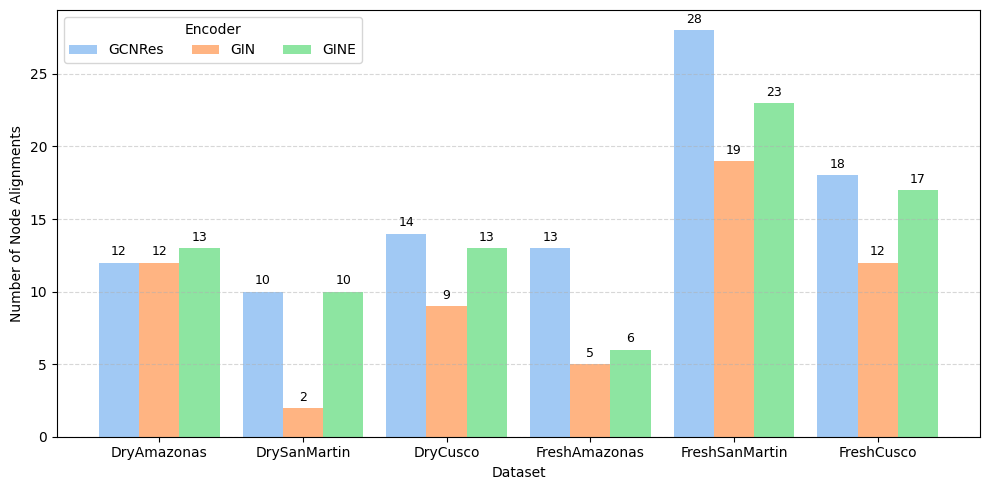

In [39]:
# Plot bar chart for comprison
save = False  # change

colors = [
	"#A1C9F4",
	"#FFB482",
	"#8DE5A1",
	"#FF9F9B",
]

# Datasets
datasets = [
	"DryAmazonas",
	"DrySanMartin",
	"DryCusco",
	"FreshAmazonas",
	"FreshSanMartin",
	"FreshCusco",
]

# Accuracy values
results = {
    "GCNRes": gcnres,
	"GIN": gin,
	"GINE": gine,
}

# Plot settings
x = np.arange(len(datasets))
width = 0.28
n_models = len(results)

fig, ax = plt.subplots(figsize=(10, 5))

# Draw bars
for i, (model, values) in enumerate(results.items()):

	# Center bars around each dataset position
	offset = (i - (n_models - 1) / 2) * width

	bars = ax.bar(
		x + offset,
		values,
		width,
		label=model,
		color=colors[i],
	)

	ax.bar_label(
		bars,
		padding=3,
		fontsize=9,
	)

# Axis labels
ax.set_xlabel("Dataset")
ax.set_ylabel("Number of Node Alignments")

# Dataset labels remain centered automatically
ax.set_xticks(x)
ax.set_xticklabels(
	datasets,
	# rotation=45,
	ha="center",
)

# ax.set_ylim(0, list_count_meta[0][3])

# Legend
ax.legend(
	title="Encoder",
	ncols=n_models,
)

# Grid
ax.grid(
	axis="y",
	linestyle="--",
	alpha=0.5,
)

plt.tight_layout()

# Export figure
if save:
	plt.savefig(
		f"experiments/output/{exp}/plots/number_node_alignment.pdf",
		format="pdf",
		bbox_inches="tight",
	)

plt.show()

Comparison with Vanessa filter

In [16]:
vanessa

[20, 33, 72, 239, 251, 252, 307, 790, 939]

In [17]:
# Comparison filter Venessa
list_data = []
retrievals = ["", "_cosine", "_l2"]

for group_id in groups_id:
	for encoder in encoders:
		for retrieval in retrievals:
			df = pd.read_csv(f"experiments/output/{exp}/common_nodes/{encoder}_{group_id}{retrieval}.csv", header=None)
			list_nodes_id = [set(vanessa)]
			list_nodes_id.append(set(df[0].values))

			intersection = set.intersection(*list_nodes_id)
			# print(f"{group_id}, {encoder}, {retrieval}, {len(intersection)}/{len(df)}")
			# print(intersection)
			list_data.append([group_id, encoder, retrieval, len(intersection), len(df), intersection])
			# print(intersection)
			# print()

In [18]:
# Include union, intersection

for retrieval in ["", "_cosine", "_l2"]:
	print(retrieval)
	for encoder in encoders:
		for group_id in ["union", "intersection"]:
			try:
				# print(f"experiments/output/{exp}/common_nodes/{encoder}_{group_id}{retrieval}.csv")
				df = pd.read_csv(f"experiments/output/{exp}/common_nodes/{encoder}_{group_id}{retrieval}.csv", header=None)
				list_nodes_id = [set(vanessa)]
				list_nodes_id.append(set(df[0].values))

				intersection = set.intersection(*list_nodes_id)
				# print(f"{group_id}, {encoder}, {retrieval}, {len(intersection)}/{len(df)}")
				# print(intersection)
				list_data.append([group_id, encoder, retrieval, len(intersection), len(df), intersection])
				# print(intersection)
				# print()
			except:
				print(f"experiments/output/{exp}/common_nodes/{encoder}_{group_id}{retrieval}.csv")
df_results = pd.DataFrame(list_data, columns=["Group", "Encoder", "Retrieval", "Common nodes", "Total nodes", "Common nodes"])
df_results


_cosine
experiments/output/exp116/common_nodes/GCN_intersection_cosine.csv
experiments/output/exp116/common_nodes/GIN_intersection_cosine.csv
experiments/output/exp116/common_nodes/GINE_intersection_cosine.csv
_l2


,Group,Encoder,Retrieval,Common nodes,Total nodes,Common nodes
0,SecoAmazonas,GCNRes,,0,37,{}
1,SecoAmazonas,GCNRes,_cosine,3,64,"{72, 307, 239}"
2,SecoAmazonas,GCNRes,_l2,3,49,"{72, 307, 239}"
3,SecoAmazonas,GCN,,1,27,{307}
4,SecoAmazonas,GCN,_cosine,2,56,"{307, 239}"
...,...,...,...,...,...,...
88,intersection,GCN,_l2,0,1,{}
89,union,GIN,_l2,3,150,"{307, 790, 239}"
90,intersection,GIN,_l2,0,1,{}
91,union,GINE,_l2,4,124,"{72, 307, 790, 239}"


In [20]:
df_results[50:]

,Group,Encoder,Retrieval,Common nodes,Total nodes,Common nodes
50,FrescoSanMartin,GCNRes,_l2,1,68,{239}
51,FrescoSanMartin,GCN,,5,39,"{939, 239, 307, 20, 790}"
52,FrescoSanMartin,GCN,_cosine,1,49,{239}
53,FrescoSanMartin,GCN,_l2,2,67,"{939, 239}"
54,FrescoSanMartin,GIN,,2,26,"{307, 239}"
55,FrescoSanMartin,GIN,_cosine,1,26,{790}
56,FrescoSanMartin,GIN,_l2,2,31,"{790, 239}"
57,FrescoSanMartin,GINE,,3,30,"{307, 20, 239}"
58,FrescoSanMartin,GINE,_cosine,1,41,{790}
59,FrescoSanMartin,GINE,_l2,3,41,"{72, 790, 239}"
